<a href="https://colab.research.google.com/github/sharakhaplan/All-Aml-Leukemia-Subtype-Classification-Using-Gene-Expression-Data/blob/main/Classification_of_ALL_and_AML.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [2]:
import os

for kok_dizin, klasorler, dosyalar in os.walk('/content/drive/MyDrive'):
    for dosya in dosyalar:
        if dosya.lower().endswith(('.csv', '.xlsx')):
            print(os.path.join(kok_dizin, dosya))

/content/drive/MyDrive/Dataset/All_Aml_Sınıflandırma_Dataset/actual.csv
/content/drive/MyDrive/Dataset/All_Aml_Sınıflandırma_Dataset/data_set_ALL_AML_independent.csv
/content/drive/MyDrive/Dataset/All_Aml_Sınıflandırma_Dataset/data_set_ALL_AML_train.csv


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

#grafik ayarları
sns.set_theme(style="whitegrid")
plt.rcParams['figure.dpi'] = 300
plt.rcParams['font.size'] = 10

print("Kütüphaneler Yüklendi,Grafik Ayarları oluşturuldu :)")

Kütüphaneler Yüklendi,Grafik Ayarları oluşturuldu :)


In [9]:
# Dosyaları yükleme
train_raw = pd.read_csv("/content/drive/MyDrive/Dataset/All_Aml_Sınıflandırma_Dataset/data_set_ALL_AML_train.csv")
test_raw = pd.read_csv("/content/drive/MyDrive/Dataset/All_Aml_Sınıflandırma_Dataset/data_set_ALL_AML_independent.csv")
actual = pd.read_csv("/content/drive/MyDrive/Dataset/All_Aml_Sınıflandırma_Dataset/actual.csv")

In [8]:
# Biyolojik 'call' (P,A,M) sütunlarını temizleme
train_cols = [c for c in train_raw.columns if "call" not in c.lower()]
test_cols = [c for c in test_raw.columns if "call" not in c.lower()]

train_clean = train_raw[train_cols]
test_clean = test_raw[test_cols]

In [10]:
# Train ve Independent verilerini gen isimleri üzerinden birleştirme
df_merged = pd.merge(train_clean, test_clean, on=['Gene Description','Gene Accession Number'])
df_merged.set_index(['Gene Accession Number', 'Gene Description'], inplace=True)

In [12]:
# Sütun isimlerini hasta ID (integer) olarak düzenleme
clean_patient_ids = [int(c) for c in df_merged.columns]
df_merged.columns = clean_patient_ids

In [13]:
# Matrisi çevirme (Satırlar: Hastalar, Sütunlar: Genler)
X_raw = df_merged.T.sort_index()

In [14]:
# actual.csv ile hasta etiketlerini eşleştirme
actual['patient'] = actual['patient'].astype(int)
actual.set_index('patient', inplace=True)
y_labels = actual.loc[X_raw.index, 'cancer']

In [15]:
# Özet bilgileri ekrana yazırma
print(f"================ VERİ ÖZETİ ================")
print(f"Toplam Hasta Sayısı (n): {X_raw.shape[0]}")
print(f"Toplam Gen Sayısı (p): {X_raw.shape[1]}")
print(f"Eksik (NaN) Değer Sayısı: {X_raw.isna().sum().sum()}")
print("\nSınıf Dağılımı:")
print(y_labels.value_counts())
print("\nYüzdesel Dağılım:")
print((y_labels.value_counts(normalize=True) * 100).round(2))




================ VERİ ÖZETİ ================
Toplam Hasta Sayısı (n): 72
Toplam Gen Sayısı (p): 7129
Eksik (NaN) Değer Sayısı: 0

Sınıf Dağılımı:
cancer
ALL    47
AML    25
Name: count, dtype: int64

Yüzdesel Dağılım:
cancer
ALL    65.28
AML    34.72
Name: proportion, dtype: float64


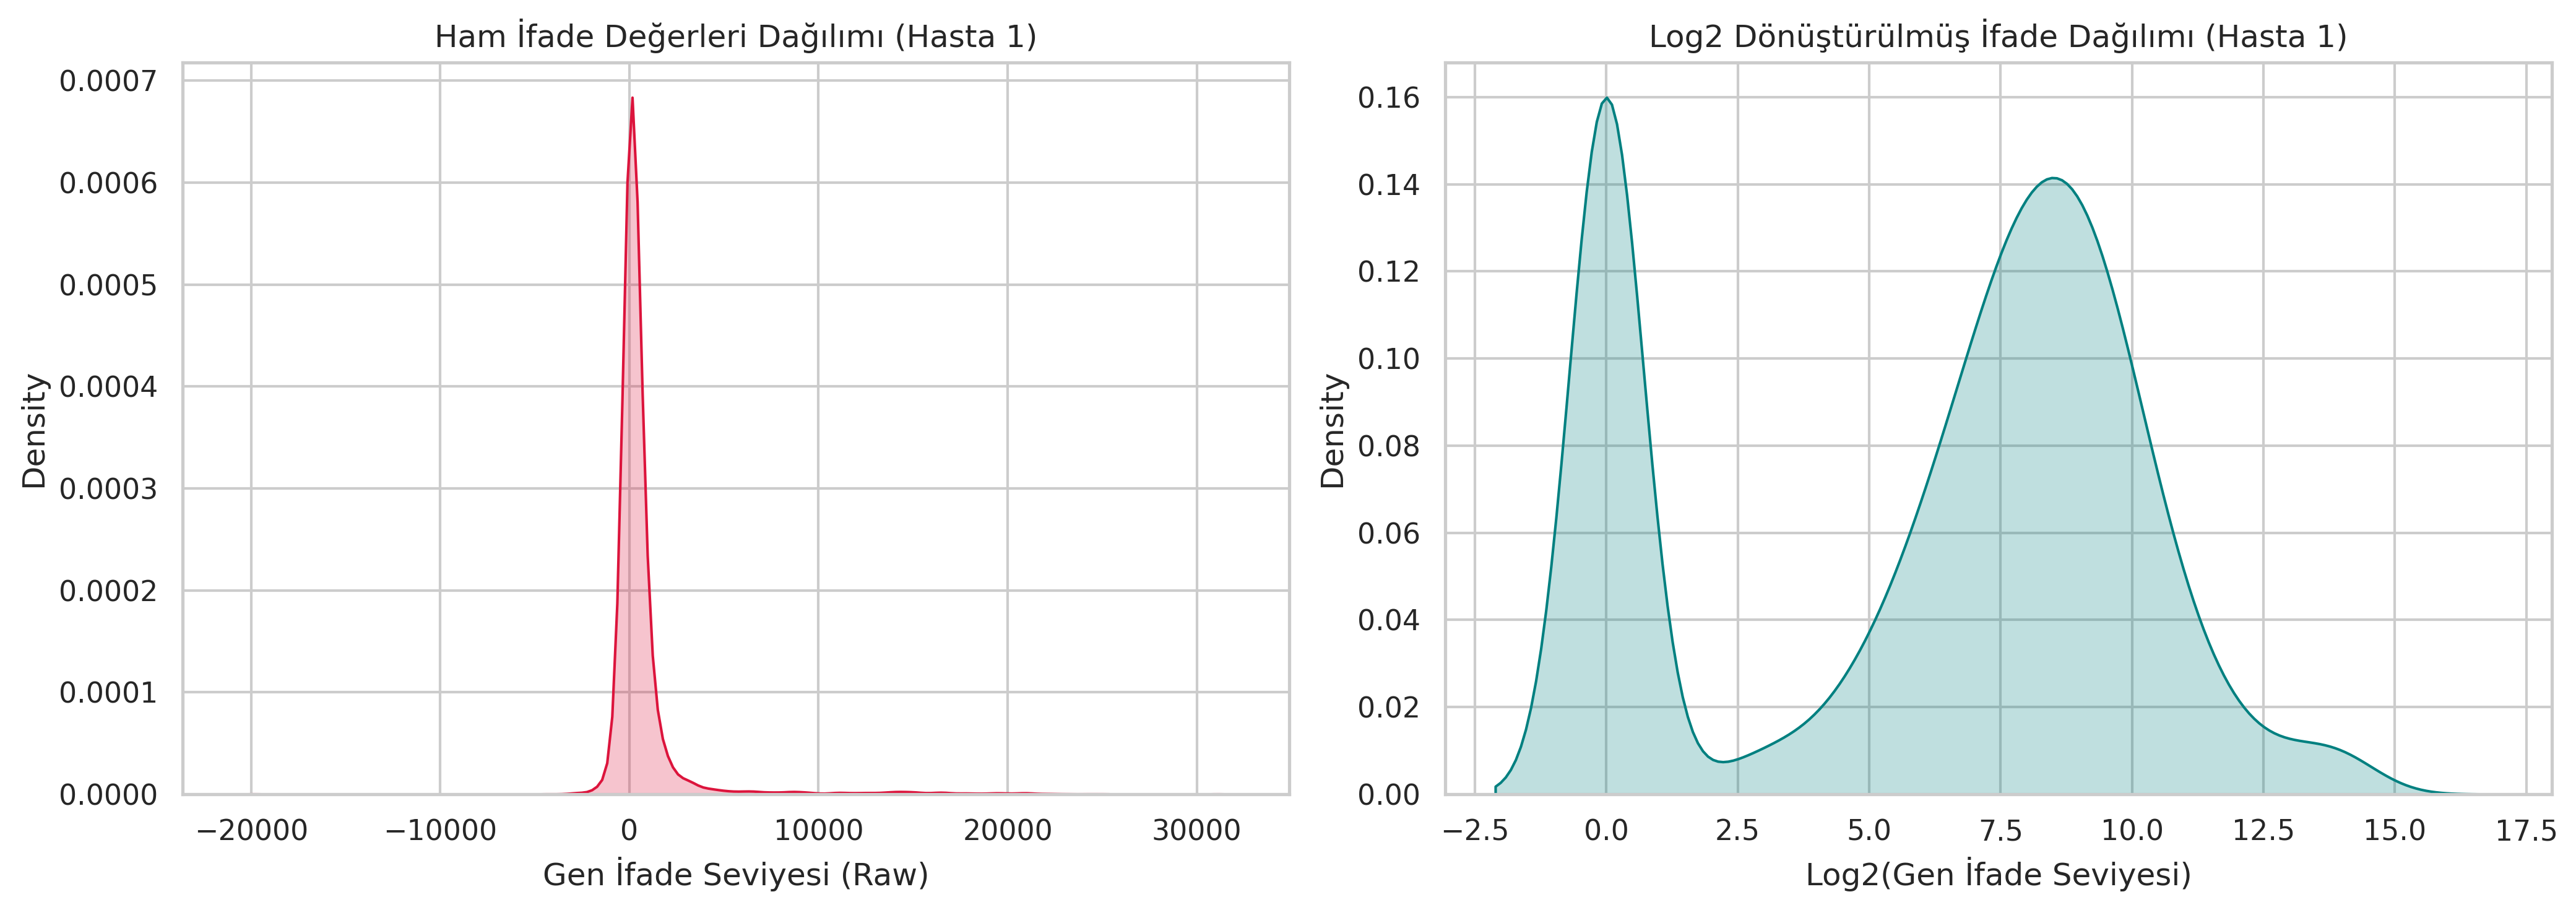

✅ Log2 dönüşümü yapıldı ve '1_log2_transformation.png' kaydedildi!


In [17]:
# Negatif ve sıfır değerleri biyolojik taban değer olan 1'e sabitleme (Thresholding)
X_floored = X_raw.clip(lower=1)

# Log2 Dönüşümü
X_log2 = np.log2(X_floored)

# Ham Veri vs Log2 Dağılım Grafiği
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.kdeplot(X_raw.iloc[0], ax=axes[0], color='crimson', fill=True)
axes[0].set_title("Ham İfade Değerleri Dağılımı (Hasta 1)")
axes[0].set_xlabel("Gen İfade Seviyesi (Raw)")
sns.kdeplot(X_log2.iloc[0], ax=axes[1], color='teal', fill=True)
axes[1].set_title("Log2 Dönüştürülmüş İfade Dağılımı (Hasta 1)")
axes[1].set_xlabel("Log2(Gen İfade Seviyesi)")
plt.tight_layout()
plt.savefig("1_log2_transformation.png")
plt.show()

print("✅ Log2 dönüşümü yapıldı ve '1_log2_transformation.png' kaydedildi!")



PC1 Açıklanan Varyans: %6.73
PC2 Açıklanan Varyans: %5.39
Toplam Açıklanan Varyans (2D): %12.12


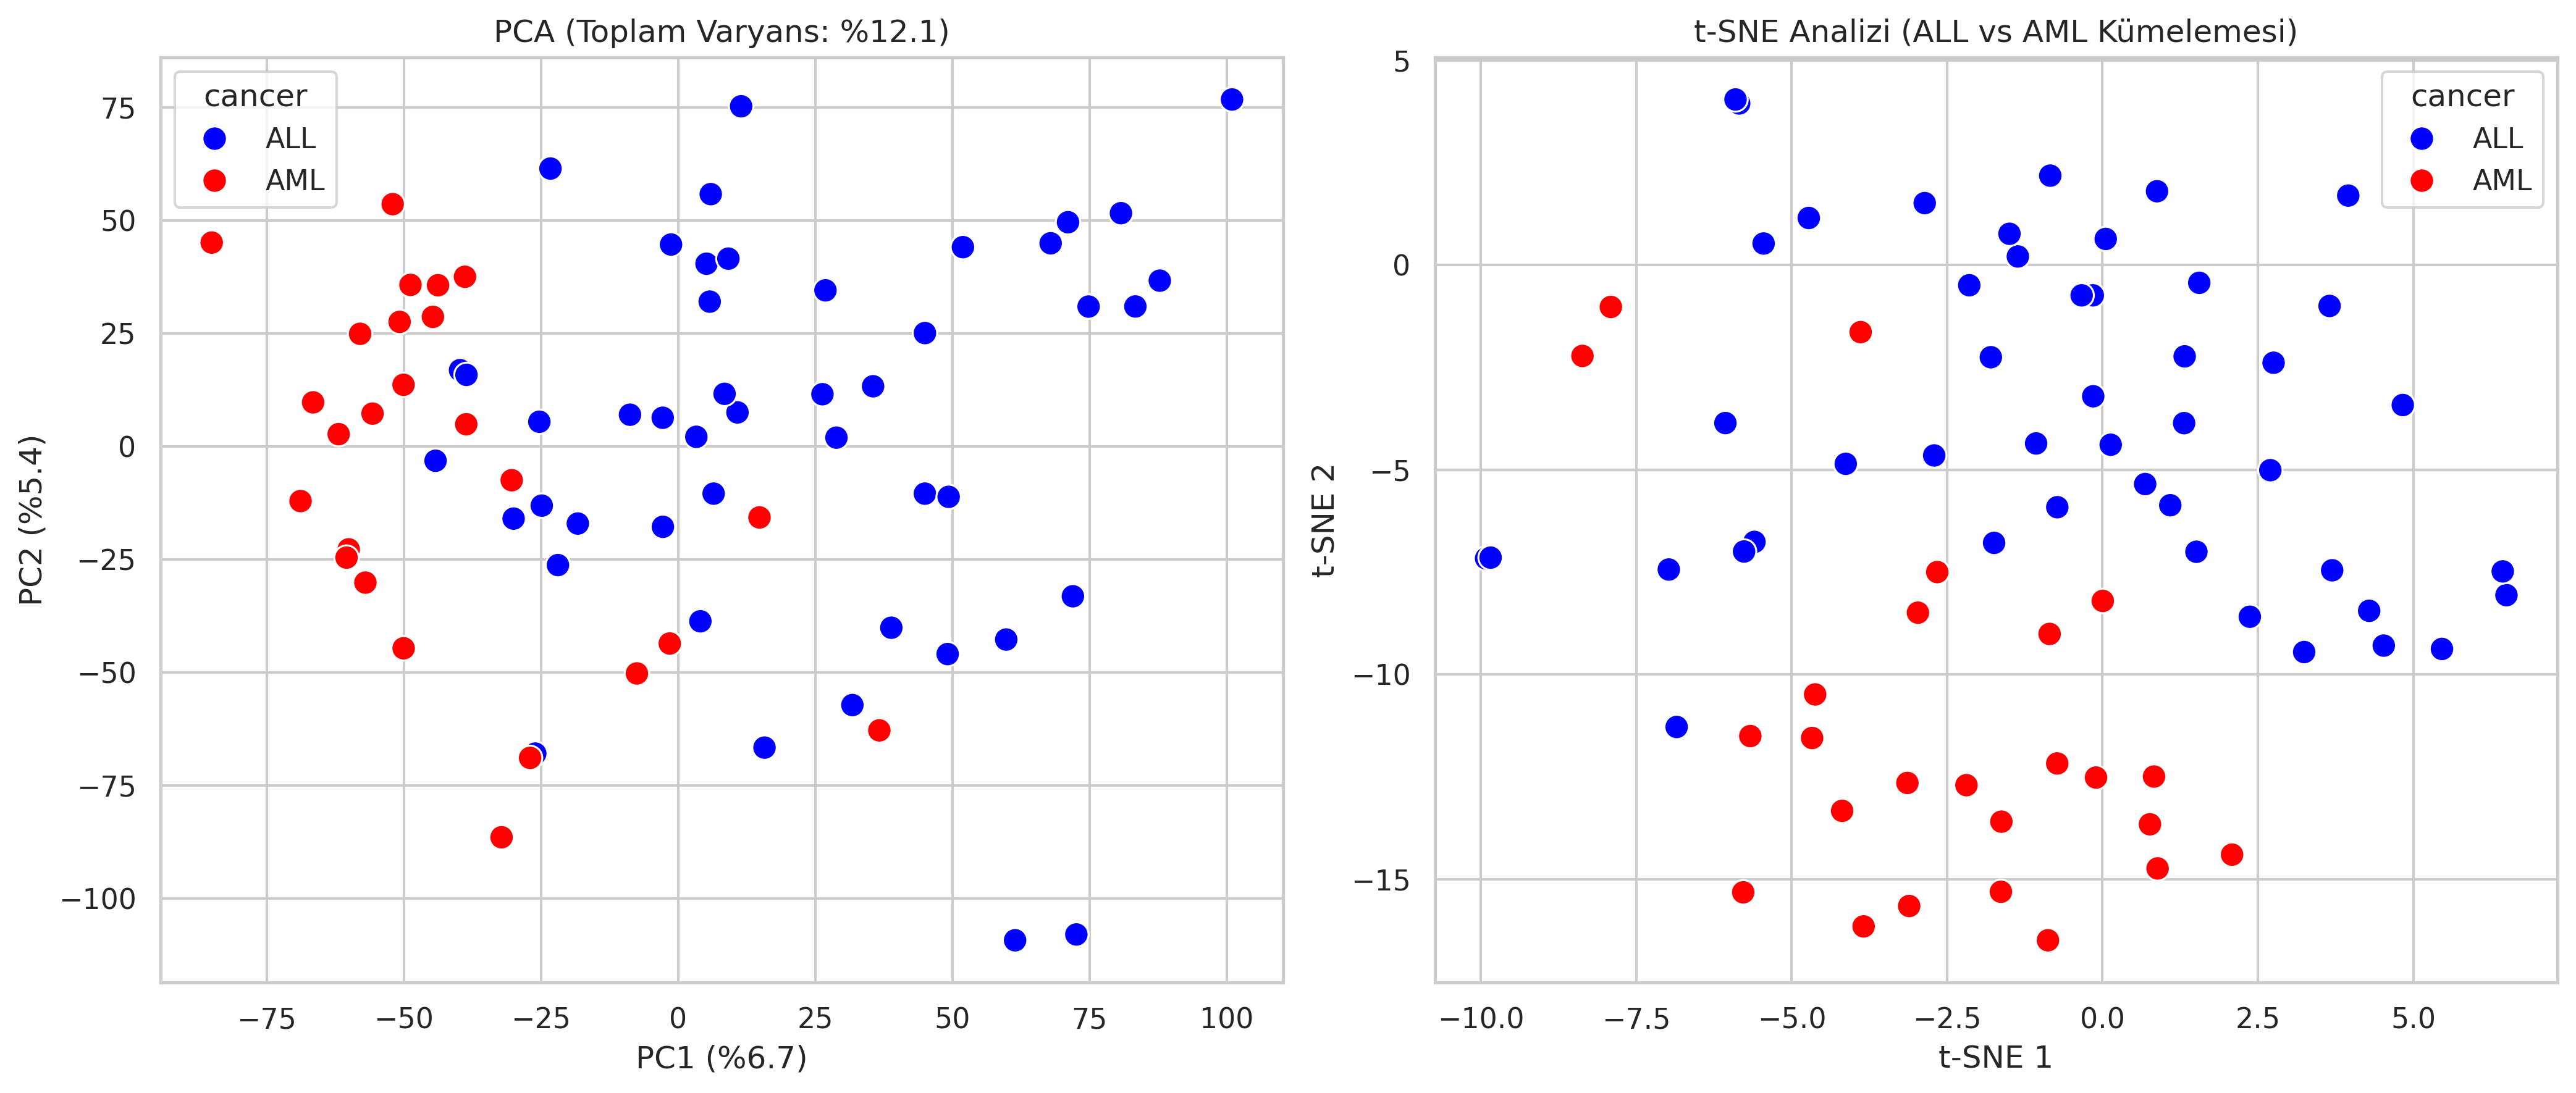

PCA ve t-SNE grafiği '2_pca_tsne_visualization.png' olarak kaydedildi!


In [18]:
# PCA Analizi
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_log2)
var_explained = pca.explained_variance_ratio_

print(f"PC1 Açıklanan Varyans: %{var_explained[0]*100:.2f}")
print(f"PC2 Açıklanan Varyans: %{var_explained[1]*100:.2f}")
print(f"Toplam Açıklanan Varyans (2D): %{sum(var_explained)*100:.2f}")

# t-SNE Analizi
tsne = TSNE(n_components=2, random_state=42, perplexity=15)
X_tsne = tsne.fit_transform(X_log2)

# Grafik Çizimi
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# PCA Grafiği
sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=y_labels, palette={'ALL': 'blue', 'AML': 'red'}, s=90, ax=axes[0])
axes[0].set_title(f"PCA (Toplam Varyans: %{sum(var_explained)*100:.1f})")
axes[0].set_xlabel(f"PC1 (%{var_explained[0]*100:.1f})")
axes[0].set_ylabel(f"PC2 (%{var_explained[1]*100:.1f})")


# t-SNE Grafiği
sns.scatterplot(x=X_tsne[:, 0], y=X_tsne[:, 1], hue=y_labels, palette={'ALL': 'blue', 'AML': 'red'}, s=90, ax=axes[1])
axes[1].set_title("t-SNE Analizi (ALL vs AML Kümelemesi)")
axes[1].set_xlabel("t-SNE 1")
axes[1].set_ylabel("t-SNE 2")

plt.tight_layout()
plt.savefig("2_pca_tsne_visualization.png")
plt.show()

print("PCA ve t-SNE grafiği '2_pca_tsne_visualization.png' olarak kaydedildi!")




/usr/local/lib/python3.13/dist-packages/seaborn/matrix.py:1113: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  self._figure.tight_layout(**tight_params)


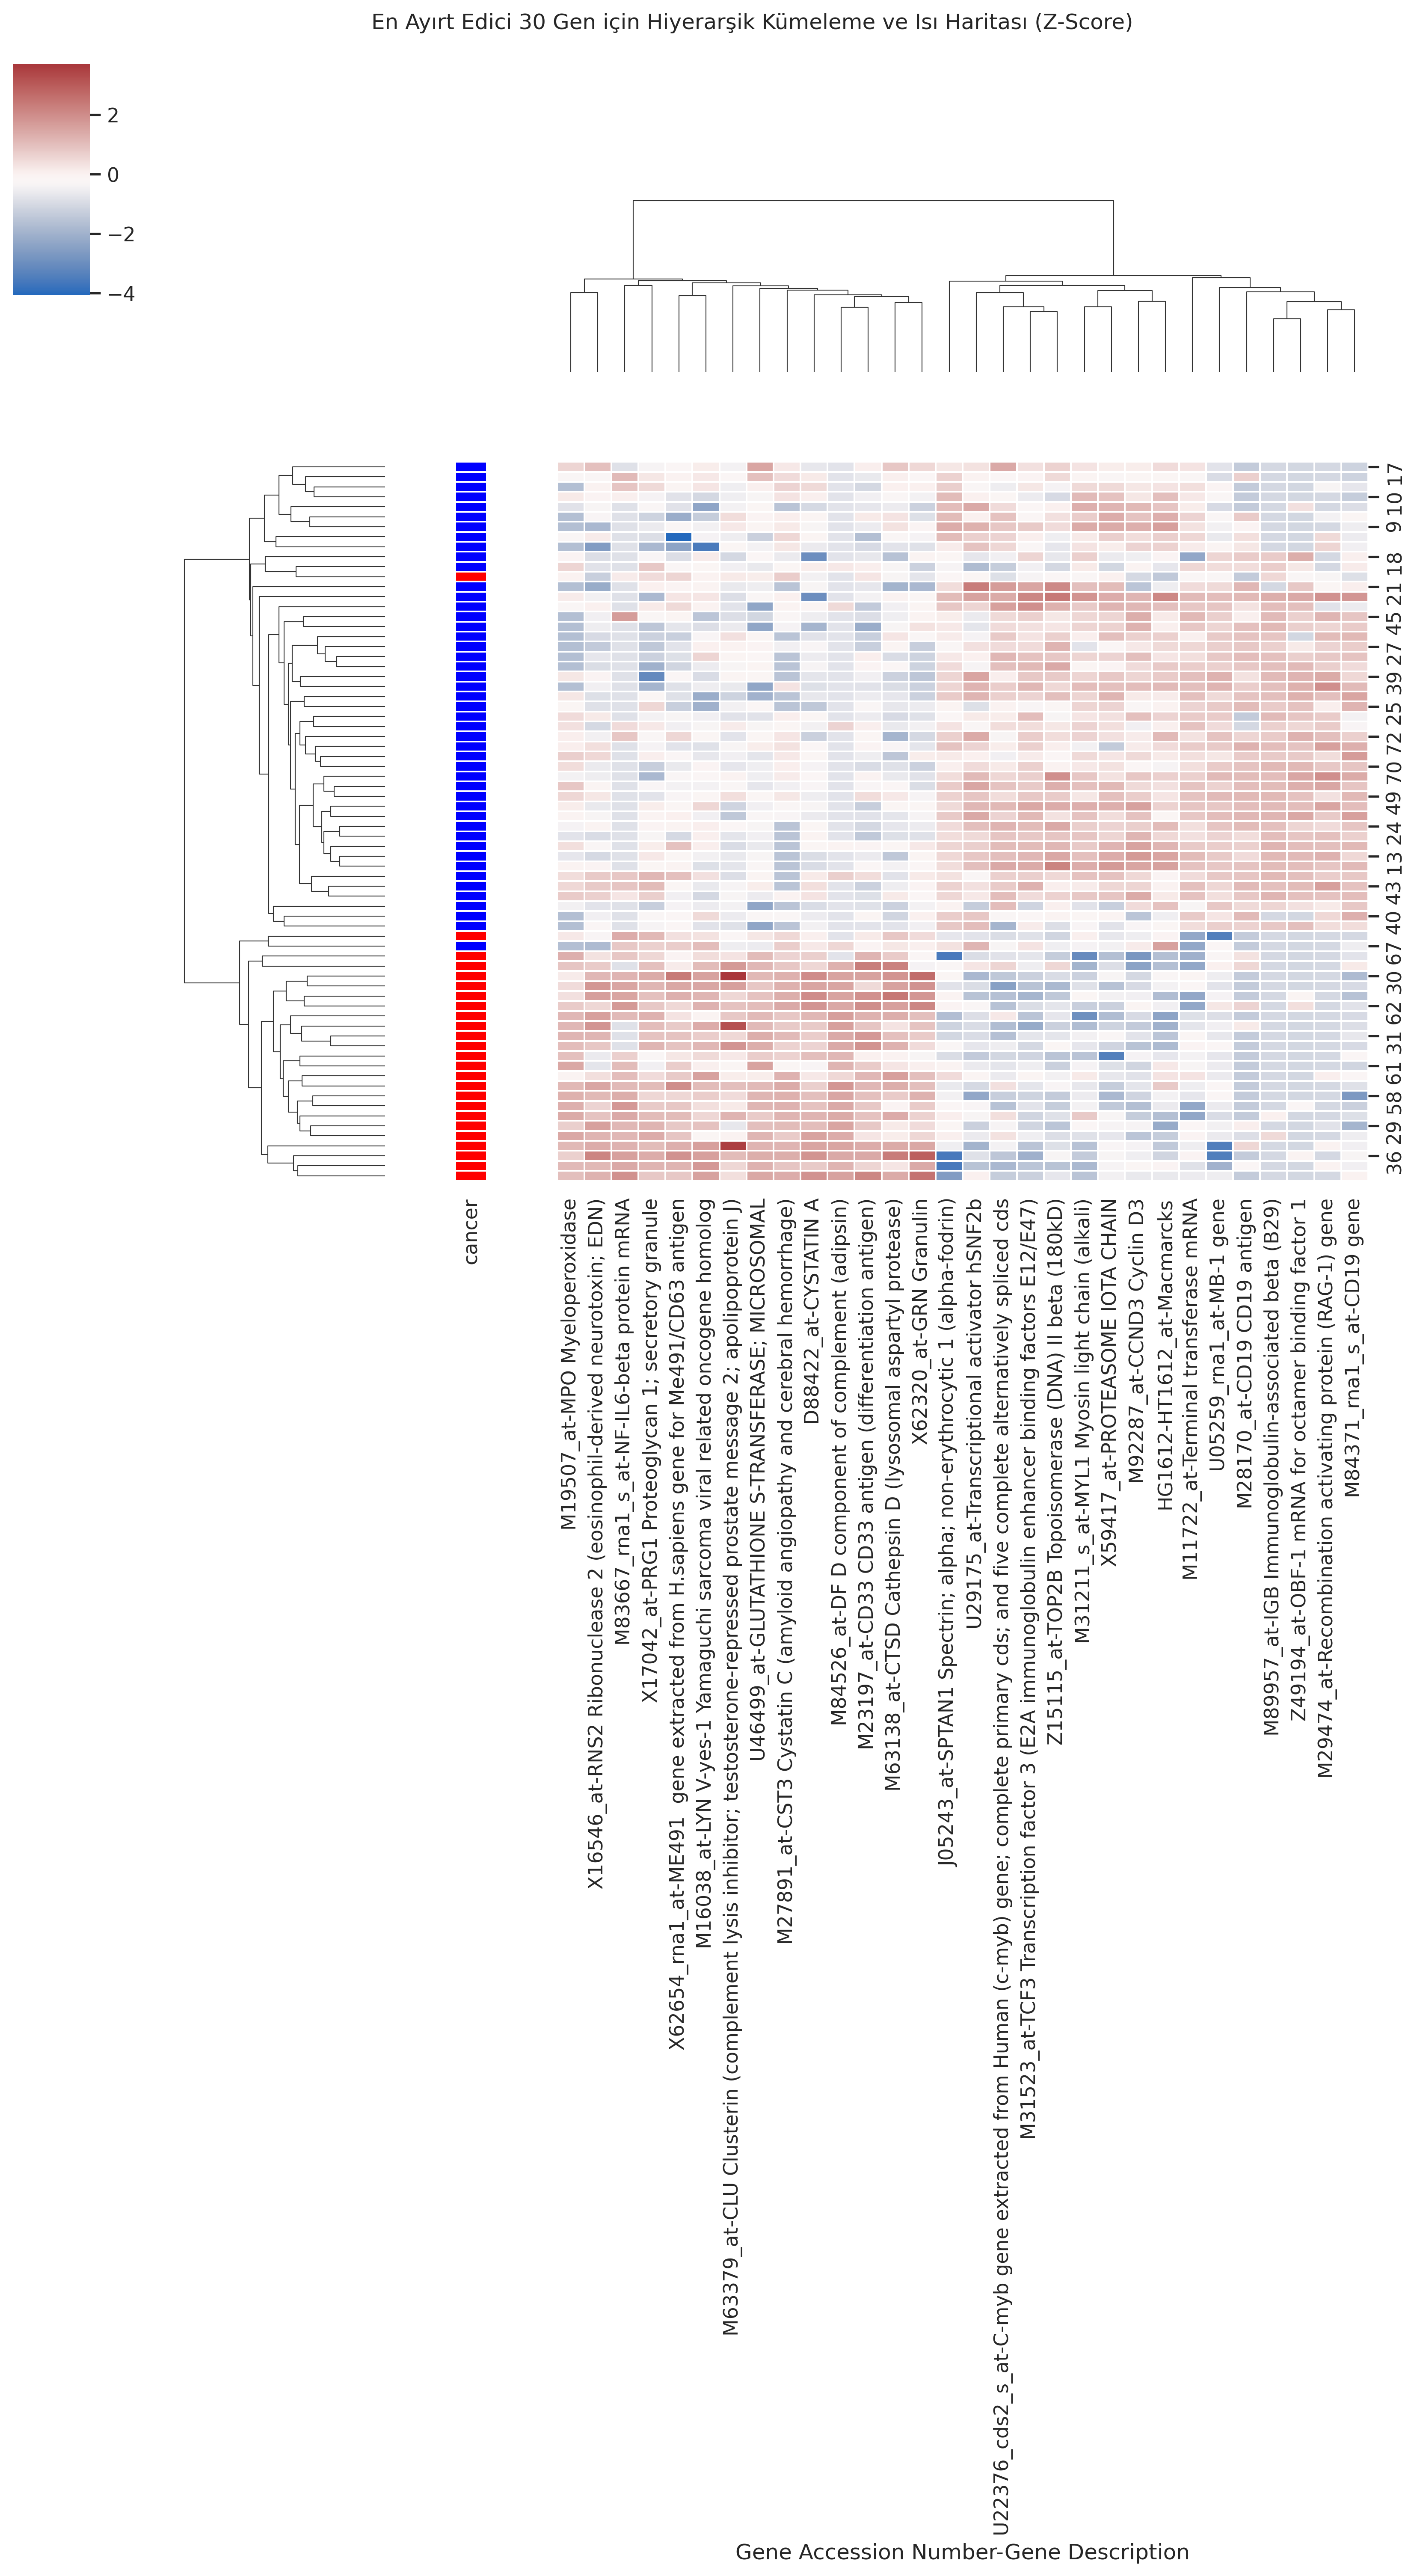

Heatmap grafiği '3_top30_genes_heatmap.png' olarak kaydedildi!


In [20]:
# ALL ve AML grupları arasında t-testi
all_mask = (y_labels == 'ALL')
aml_mask = (y_labels == 'AML')

p_values = {}
for col in X_log2.columns:
    stat, p = stats.ttest_ind(X_log2.loc[all_mask, col], X_log2.loc[aml_mask, col])
    p_values[col] = p
p_series = pd.Series(p_values)
top30_genes = p_series.nsmallest(30).index

# En ayırt edici 30 gen matrisi
X_top30 = X_log2[top30_genes]

# Etiket renk haritası (ALL: Mavi, AML: Kırmızı)
lut = {'ALL': 'blue', 'AML': 'red'}
row_colors = y_labels.map(lut)

# Clustermap (Heatmap + Hiyerarşik Kümeleme)
g = sns.clustermap(X_top30, row_colors=row_colors, cmap="vlag", z_score=1,
                   figsize=(12, 10), linewidths=0.5)

g.fig.suptitle("En Ayırt Edici 30 Gen için Hiyerarşik Kümeleme ve Isı Haritası (Z-Score)", y=1.02)
plt.savefig("3_top30_genes_heatmap.png", bbox_inches='tight')
plt.show()

print("Heatmap grafiği '3_top30_genes_heatmap.png' olarak kaydedildi!")


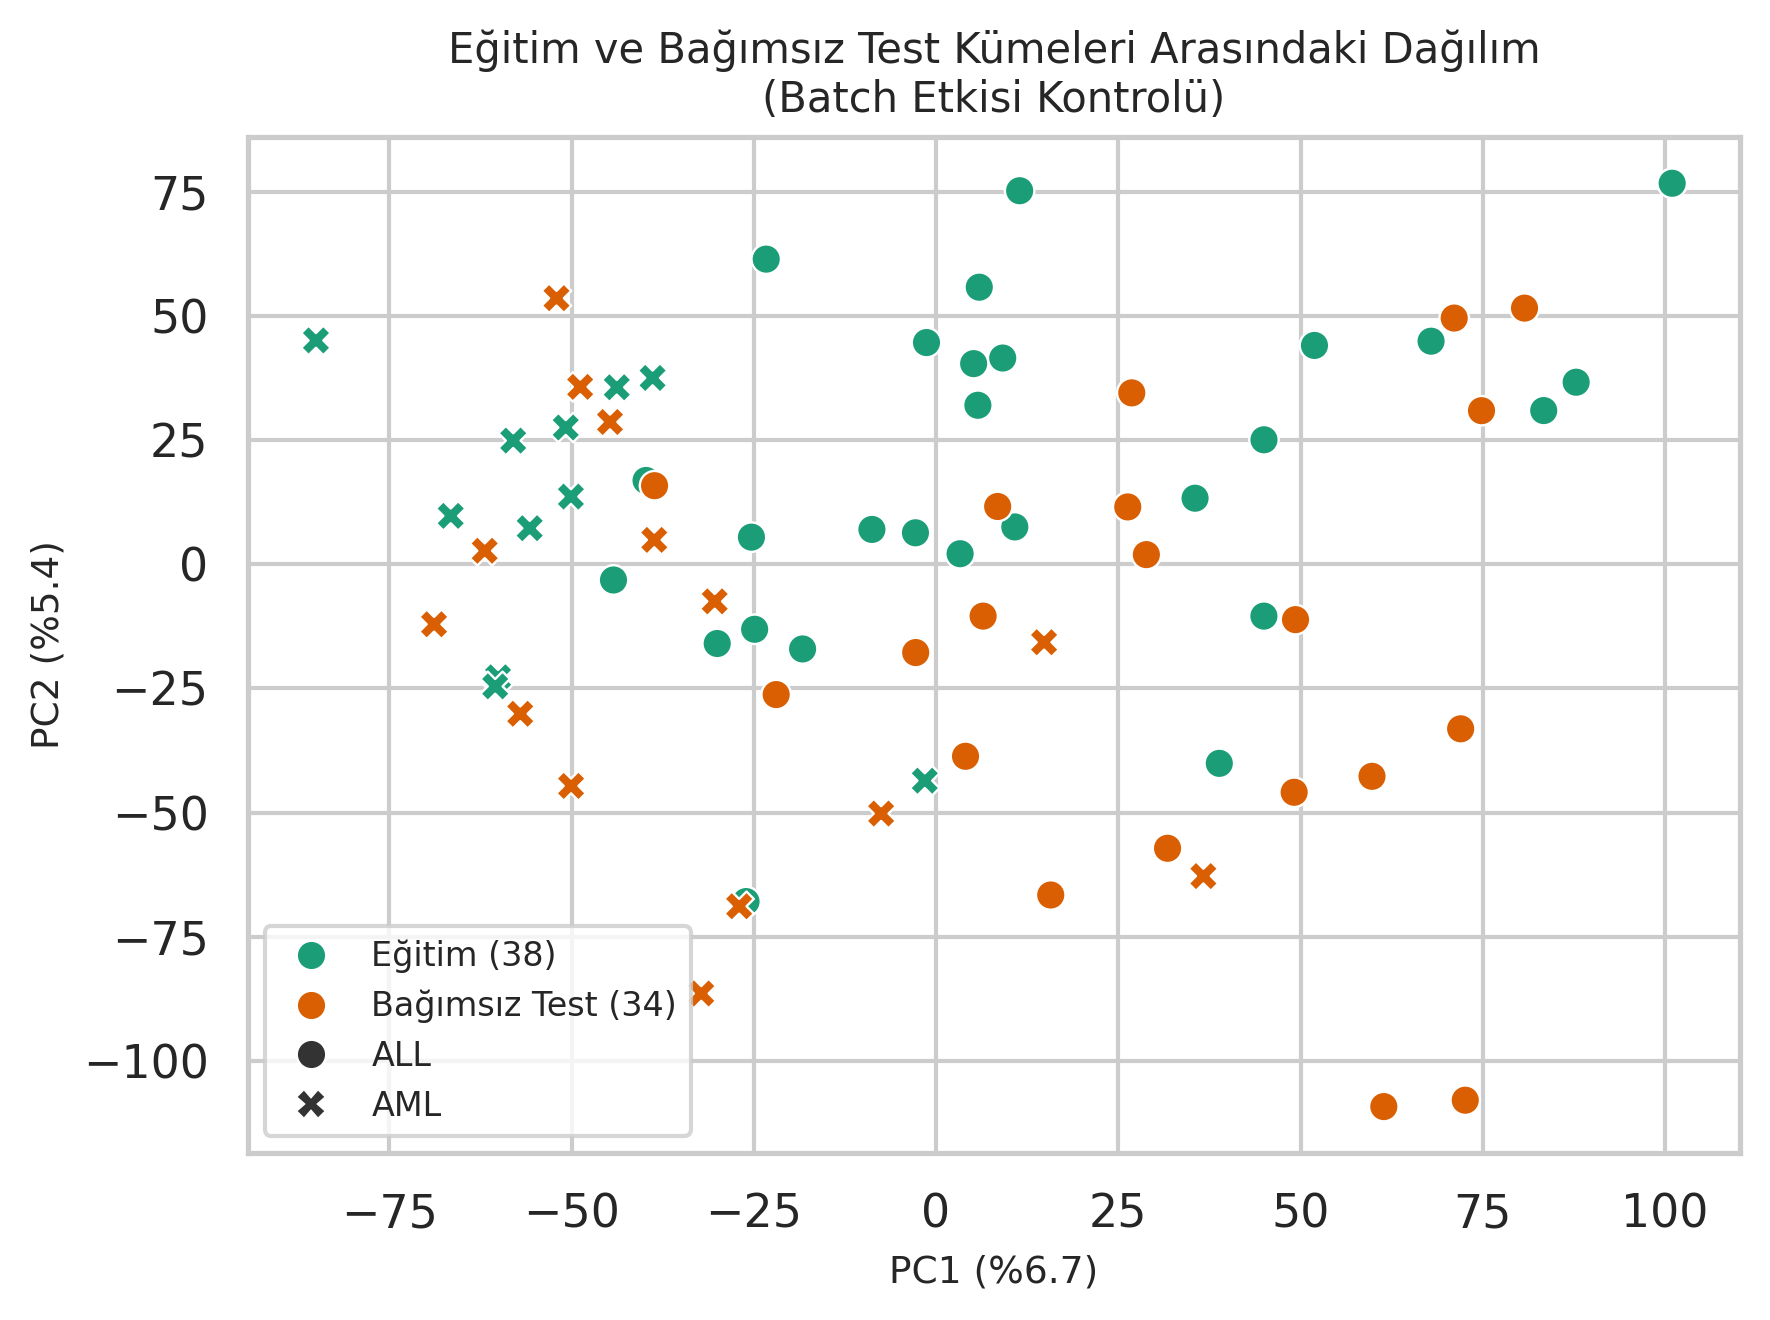

Batch etkisi kontrolü tamamlandı ve '4_batch_effect_check.png' olarak kaydedildi!


In [22]:
# Train ve Independent ayrım etiketi
train_ids = [int(c) for c in train_clean.columns if c not in ['Gene Description', 'Gene Accession Number']]
dataset_source = ['Eğitim (38)' if idx in train_ids else 'Bağımsız Test (34)' for idx in X_log2.index]

plt.figure(figsize=(6, 4.5))
sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=dataset_source,
                style=y_labels, palette='Dark2', s=50)   # nokta boyutu 90 -> 50
plt.title("Eğitim ve Bağımsız Test Kümeleri Arasındaki Dağılım\n(Batch Etkisi Kontrolü)", fontsize=10)
plt.xlabel(f"PC1 (%{var_explained[0]*100:.1f})", fontsize=9)
plt.ylabel(f"PC2 (%{var_explained[1]*100:.1f})", fontsize=9)
plt.legend(fontsize=8, loc='best')

plt.tight_layout()
plt.savefig("4_batch_effect_check.png", dpi=150)
plt.show()
print("Batch etkisi kontrolü tamamlandı ve '4_batch_effect_check.png' olarak kaydedildi!")

